# EDA пробного оценочного набора

Пробный прогон перед генерацией основного набора: 10 вопросов × 6 сценариев = 60 ответов, 270 решений по тезисам.
Ответы пишут две модели из других семейств, чем проверяющая: `openai/gpt-6.1-terra` и `google/gemini-4-hydrogen`,
по 30 ответов. Метка каждого тезиса задана карточкой сценария («по построению»). Генерация — `eval/generate.py`.

Вопросы анализа:

1. **Шум меток:** совпадает ли написанное с карточкой? Проверка — слепая разметка (без карточек) всех 60 ответов.
2. **Утечка формулировок:** насколько ответ повторяет слова тезисов — от этого зависит честность бейзлайна по ключевым словам.
3. **Первый прогон проверяющей модели** (текущий промпт приложения, v0) и стоимость.

**Ограничение.** Слепую разметку делала LLM (Claude Opus) — того же семейства, что проверяющая модель (Claude Haiku).
Их ошибки могут совпадать, поэтому сравнение Haiku с этой разметкой может быть завышено; сравнение с карточками от
этого не зависит.

In [1]:
import json
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / "app").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from eval.generate import ONE_OF, load_questions  # noqa: E402

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
TRIAL = ROOT / "eval" / "trial"


def read(name):
    return {r["card_id"]: r for r in map(json.loads, (TRIAL / name).read_text(encoding="utf-8").splitlines())}


bank, cards, answers = load_questions(), read("cards.jsonl"), read("answers.jsonl")
review, judge = read("review.jsonl"), read("judge_v0.jsonl")

rows = []
for cid, c in cards.items():
    q = bank[c["question_id"]]
    for n, thesis in enumerate(q.rubric):
        rows.append(
            {
                "card": cid,
                "generator": c["generator"].split("/")[0],
                "scenario": c["scenario"],
                "thesis": thesis,
                "kind": "хотя бы один" if ONE_OF.search(thesis) else "прочие",
                "card_label": c["statuses"][n],
                "review": review[cid]["statuses"][n],
                "judge": judge[cid]["statuses"][n],
                "answer": answers[cid]["answer"],
            }
        )
df = pd.DataFrame(rows)
LABELS = ["hit", "partial", "miss"]
print(f"ответов: {df.card.nunique()}, тезисов: {len(df)}")
df["card_label"].value_counts().reindex(LABELS).rename("тезисов по карточкам").to_frame().T

ответов: 60, тезисов: 270


card_label,hit,partial,miss
тезисов по карточкам,91,84,95


Классы сбалансированы намеренно: в смешанных сценариях «частично» выпадает чаще, потому что в сильном и слабом
сценариях его нет. Тезисам с мерой «хотя бы один» «частично» не назначается: назвать любой вариант из списка — уже
раскрыть тезис.

## 1. Шум меток

In [2]:
df["agree"] = df["card_label"] == df["review"]
by_class = df.groupby("card_label")["agree"].mean().reindex(LABELS)
by_gen = df.groupby("generator")["agree"].mean()
print(f"Совпадение разметки с карточками: {df.agree.mean():.0%}")
display(pd.concat({"по классу карточки": by_class, "по генератору": by_gen}).rename("совпадение").to_frame().T.round(2))
pd.crosstab(df.card_label, df.review, rownames=["карточка"], colnames=["разметка"]).reindex(
    index=LABELS, columns=LABELS
)

Совпадение разметки с карточками: 91%


по классу карточки               по генератору       
                          hit partial  miss        google openai
совпадение               0.99    0.75  0.98          0.89   0.93

разметка,hit,partial,miss
карточка,,,
hit,90,1,0
partial,19,63,2
miss,0,2,93


**Вывод.** «Раскрыт» и «не раскрыт» генераторы воспроизводят почти без ошибок, шум сосредоточен в «частично»
(около четверти). Почти все расхождения — «частично» по карточке, «раскрыт» по разметке. Типичные случаи:

In [3]:
examples = {
    "la-mcoll-005#s6": 0,  # выкинута деталь в скобках
    "stprob-binom-015#s3": 0,  # посчитано среднее 50, слово «биномиальное» не произнесено
    "mll-imb-015#s3": 0,  # названа взвешенная cross-entropy, не сказано «первый шаг»
}
for cid, n in examples.items():
    said = next(x["said"] for x in answers[cid]["theses"] if x["n"] == n + 1)
    print(f"{cid}\n  тезис: {bank[cards[cid]['question_id']].rubric[n]}\n  генератор считает, что пропустил: {said}\n")

la-mcoll-005#s6
  тезис: Сказал, что $X^TX$ становится почти вырожденной (определитель и минимальное собственное значение близки к нулю)
  генератор считает, что пропустил: Сказано, что матрица X^T X становится почти вырожденной, но не упомянуты определитель и минимальное собственное значение.

stprob-binom-015#s3
  тезис: Определил биномиальное распределение и посчитал среднее 50
  генератор считает, что пропустил: Посчитано среднее 50, но не названо биномиальное распределение

mll-imb-015#s3
  тезис: Назвал взвешивание классов в cross-entropy как первый шаг
  генератор считает, что пропустил: Названа взвешенная cross-entropy, но не сказано, что это первый шаг.



Генератор делает «частично», убирая **деталь** (уточнение в скобках, термин, оговорку «как первый шаг»), а суть
оставляет — читатель видит суть и ставит «раскрыт». Проверяющая модель в этих местах тоже ставит «раскрыт» (раздел 3),
то есть ошибается карточка, а не проверка.

**Решения.**

1. В промпт генератора — правило разметки: «частично» убирает суть, а не деталь; суть без термина — «раскрыт»; уточнения
   в скобках и примеры не обязательны.
2. Тезисы с уточнениями в скобках и оговорками — кандидаты на правку при экспертной проверке банка.
3. Перед основной генерацией — повторный пробный прогон с исправленным промптом.

## 2. Утечка формулировок

Если ответы повторяют слова тезисов, бейзлайн по ключевым словам на синтетике будет нечестно хорош. Считаем долю
слов тезиса (по основам, без первого глагола), которые встречаются в ответе, отдельно по меткам.

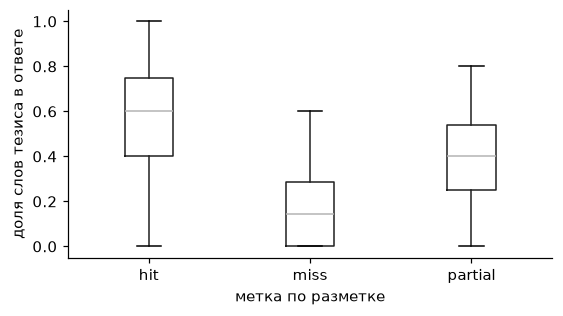

ROC-AUC «раскрыт» против «не раскрыт» по одной этой доле: 0.89


,0.25,0.50,0.75
review,,,
hit,0.40,0.60,0.75
partial,0.25,0.40,0.54
miss,0.00,0.14,0.29


In [4]:
def stems(text):
    return {w[:5] for w in re.findall(r"[a-zа-яё]{4,}", text.lower())}


df["overlap"] = [
    len(stems(" ".join(t.split()[1:])) & stems(a)) / max(len(stems(" ".join(t.split()[1:]))), 1)
    for t, a in zip(df.thesis, df.answer, strict=True)
]
ax = df.boxplot(column="overlap", by="review", positions=None, figsize=(5.5, 3), grid=False)
ax.set_xlabel("метка по разметке")
ax.set_ylabel("доля слов тезиса в ответе")
ax.set_title("")
plt.suptitle("")
plt.show()
extremes = df[df.review != "partial"]
print(
    f"ROC-AUC «раскрыт» против «не раскрыт» по одной этой доле: {roc_auc_score(extremes.review == 'hit', extremes.overlap):.2f}"
)
df.groupby("review")["overlap"].quantile([0.25, 0.5, 0.75]).unstack().reindex(LABELS).round(2)

**Вывод.** Дословного копирования нет (медиана для «раскрыт» — около 60% слов тезиса), но одна доля общих слов уже
хорошо отделяет «раскрыт» от «не раскрыт»; «частично» лежит между ними и перекрывается с обоими. Значит, бейзлайн по
ключевым словам на синтетике будет сильным — и, возможно, сильнее, чем на живых ответах: генератор видел текст тезисов
и мог тянуть из него слова, а живой кандидат его не видит.

**Решения.** Качество бейзлайна по ключевым словам сравнивать на синтетике и на живом срезе отдельно; если на живом
оно заметно ниже, синтетика завышает его. В промпт генератора — просить своими словами, без терминов тезиса там, где
есть естественный синоним.

## 3. Проверяющая модель v0 и стоимость

In [5]:
def scores(ref):
    out = {"macro-F1": f1_score(df[ref], df.judge, labels=LABELS, average="macro")}
    out |= dict(zip(LABELS, f1_score(df[ref], df.judge, labels=LABELS, average=None), strict=True))
    for g, part in df.groupby("generator"):
        out[g] = f1_score(part[ref], part.judge, labels=LABELS, average="macro")
    return out


display(pd.DataFrame({"против карточек": scores("card_label"), "против разметки": scores("review")}).T.round(2))

cost = pd.DataFrame(
    [{"шаг": f"генерация, {a['generator']}", "cost": a["cost"]} for a in answers.values()]
    + [{"шаг": f"проверка, {j['model']}", "cost": j["cost"]} for j in judge.values()]
)
cost.groupby("шаг")["cost"].agg(["count", "mean", "sum"]).rename(
    columns={"count": "вызовов", "mean": "$ за ответ", "sum": "$ всего"}
).round(4)

,macro-F1,hit,partial,miss,google,openai
против карточек,0.85,0.86,0.75,0.95,0.80,0.90
против разметки,0.89,0.92,0.80,0.96,0.83,0.95


,вызовов,$ за ответ,$ всего
шаг,,,
"генерация, google/gemini-4-hydrogen",30,0.0084,0.2515
"генерация, openai/gpt-6.1-terra",30,0.0025,0.0746
"проверка, anthropic/claude-haiku-5.5",60,0.0004,0.0259


**Вывод.**

- Текущий промпт проверяющей модели уже даёт macro-F1 около 0,85 против карточек; слабый класс — «частично». Часть
  ошибок — шум самих карточек из раздела 1. На 270 тезисах это ориентир, а не оценка: доверительный интервал широкий.
- На ответах Gemini качество ниже, но разница смешана с более шумными карточками Gemini — разделить их можно только
  после исправления промпта генератора.
- Проверка одного ответа стоит меньше $0,001 — запас до предела $0,005 большой (в продукте к ней добавляется
  распознавание речи).

## Итог

| Находка | Решение |
|---|---|
| Шум меток в «частично» ~25%: генератор убирает деталь, а не суть | правило разметки — в промпт генератора; повторный пробный прогон |
| «Хотя бы один» без «частично» и составные тезисы размечаются надёжно (100% и 94%) | правила оставить |
| Тезисы с уточнениями в скобках неоднозначны | правка при экспертной проверке банка |
| Доля слов тезиса в ответе отделяет «раскрыт» от «не раскрыт» (AUC ~0,9) | бейзлайн по ключевым словам сравнивать на синтетике и живом срезе отдельно |
| GPT точнее по карточкам и втрое дешевле; слабые ответы GPT звучат неестественно | основной генератор — GPT, промпт для слабых ответов исправить; Gemini — только если после исправления качество проверки на двух генераторах заметно различается |
| Haiku v0: macro-F1 ~0,85, слабое место — «частично» | точка отсчёта для этапа 2